# EN3160 Assignment 02 - Question 1

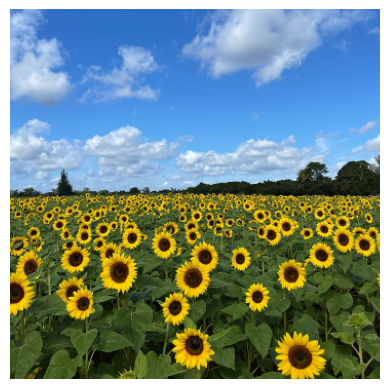

In [52]:

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

img = cv.imread("a2images/the_berry_farms_sunflower_field.jpeg",
                cv.IMREAD_REDUCED_COLOR_4)

assert img is not None, "Image not found"

plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.show()


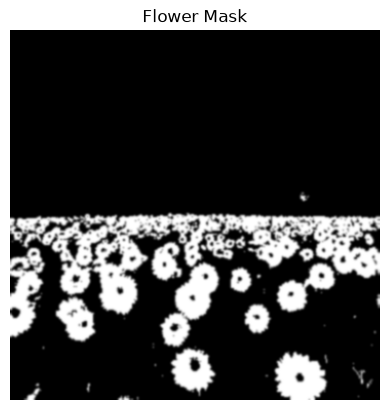

In [53]:

b, g, r = [c.astype(np.float32)/255 for c in cv.split(img)]

f = ((r > 0.95*g) & (r-b > 0.12)).astype(np.float32)
f = cv.GaussianBlur(f, (0,0), 1)

plt.imshow(f, cmap="gray")
plt.title("Flower Mask")
plt.axis("off")
plt.show()


In [54]:

sigmas = 3 * 1.2**np.arange(14)   # Approximately 3 to 32

scale_space = []

for sigma in sigmas:
    blur = cv.GaussianBlur(f, (0,0), sigma)
    lap = cv.Laplacian(blur, cv.CV_32F, ksize=3)
    scale_space.append(-sigma**2 * lap)

volume = np.array(scale_space)

print("Sigma range:", sigmas[0], "to", sigmas[-1])


Sigma range: 3.0 to 32.09796161372158


In [55]:

local_max = volume == maximum_filter(volume, size=(3,3,3))

peaks = local_max & (volume > 0.3)
peaks[0] = peaks[-1] = False

blobs = np.argwhere(peaks)

print("Candidate blobs:", len(blobs))


Candidate blobs: 104


In [56]:

candidates = sorted(
    [(x, y, np.sqrt(2)*sigmas[s], sigmas[s], volume[s,y,x])
     for s,y,x in blobs],
    key=lambda c: -c[4]
)

circles = []

for c in candidates:
    if all(np.hypot(c[0]-d[0], c[1]-d[1]) >=
           0.8*max(c[2],d[2]) for d in circles):
        circles.append(c)

circles.sort(key=lambda c: -c[2])

print("Detected circles:", len(circles))


Detected circles: 71


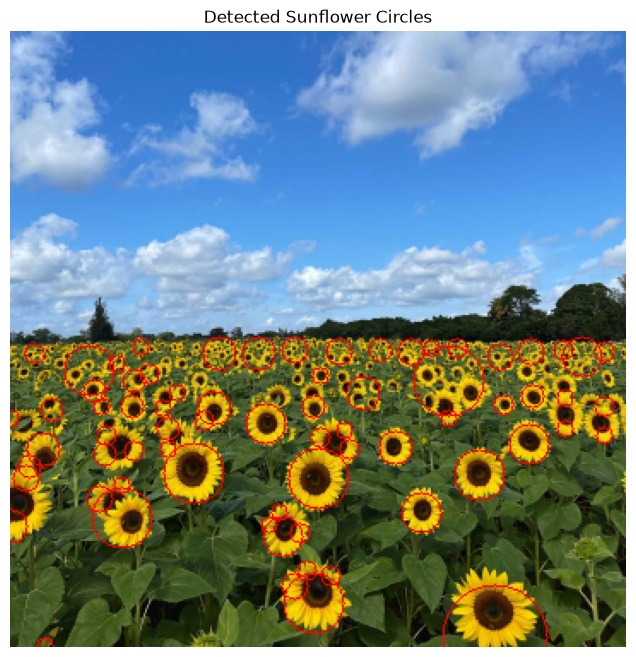

In [57]:

out = cv.cvtColor(img, cv.COLOR_BGR2RGB).copy()

for x,y,r,_,_ in circles:
    cv.circle(out, (int(x),int(y)), int(r), (255,0,0), 1)

plt.figure(figsize=(8,8))
plt.imshow(out)
plt.title("Detected Sunflower Circles")
plt.axis("off")
plt.show()


In [58]:

print("Largest 5 circles:")
print("  X    Y    Radius    Sigma")

for x,y,r,s,_ in circles[:5]:
    print(f"{x:3d}  {y:3d}   {r:6.2f}   {s:6.2f}")

print(f"\nSigma range: {sigmas[0]:.2f} to {sigmas[-1]:.2f}")


Largest 5 circles:
  X    Y    Radius    Sigma
283  354    31.52    22.29
256  204    21.89    15.48
177  334    18.24    12.90
 65  284    18.24    12.90
107  258    18.24    12.90

Sigma range: 3.00 to 32.10


## Question 2


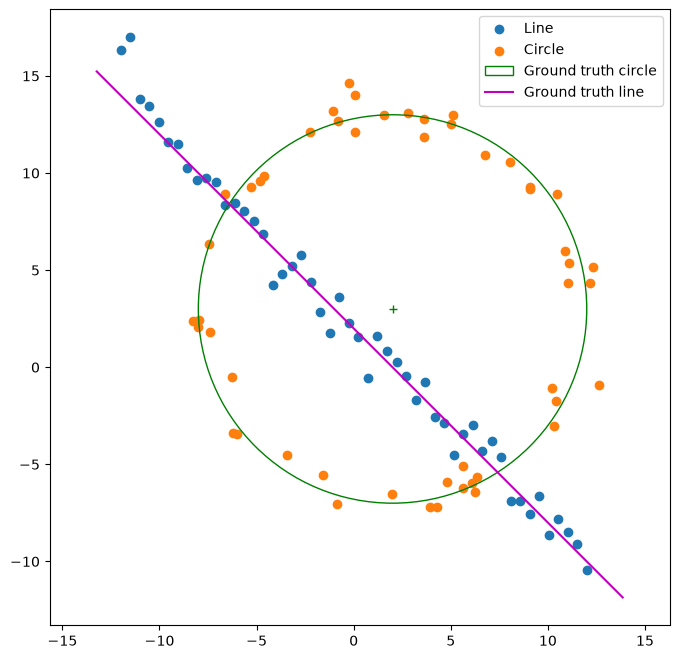

In [59]:

# Generation of a Noisy Point Set Conforming to a Line and a Circle
import numpy as np
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt

# np.random.seed(0)
N = 100
half_n = N//2
r = 10
x0_gt, y0_gt = 2, 3 # Center
s = r/16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line)) # All points

fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(X_line[:,0], X_line[:,1], label='Line')
ax.scatter(X_circ[:,0], X_circ[:,1], label='Circle')
circle_gt = plt.Circle((x0_gt, y0_gt), r, color='g',
                       fill=False, label='Ground truth circle')
ax.add_patch(circle_gt)
ax.plot((x0_gt), (y0_gt), '+', color='g')
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m*x_ + b
plt.plot(x_, y_, color='m', label='Ground truth line')
plt.legend()
plt.axis('equal')
plt.show()


## Part (a) – Implement RANSAC to fit the line

In [60]:

threshold_line = 1.5
min_line = 35
best_count = 0

for i in range(1000):
    sample = X[np.random.choice(len(X), 2, replace=False)]
    dx, dy = sample[1]-sample[0]
    norm = np.hypot(dx, dy)

    if norm == 0:
        continue

    a, b = dy/norm, -dx/norm
    d = a*sample[0,0] + b*sample[0,1]

    error = np.abs(a*X[:,0] + b*X[:,1] - d)
    inliers = error < threshold_line

    if inliers.sum() > best_count and inliers.sum() >= min_line:
        best_count = inliers.sum()
        line_model = np.array([a,b,d])
        line_inliers = inliers
        line_sample = sample

print("Line RANSAC model:", line_model)
print("Line inliers:", best_count)


Line RANSAC model: [-0.75604984 -0.65451404 -1.60747087]
Line inliers: 58


In [61]:

X_ = X[line_inliers]

U = X_ - np.mean(X_, axis=0)

_, _, Vt = np.linalg.svd(np.transpose(U) @ U)

a, b = Vt[-1, 0], Vt[-1, 1]
d = a*np.mean(X_[:,0]) + b*np.mean(X_[:,1])

best_model_line = np.array([a,b,d])

print("Best line model:", best_model_line)
print("Normal magnitude:", np.sqrt(a*a+b*b))


Best line model: [0.73222654 0.68106116 1.48808642]
Normal magnitude: 1.0


## Part (b) – Circle fitting with RANSAC

Remove line inliers

In [62]:

X_rem = X[~line_inliers]

print("Remaining points:", len(X_rem))


Remaining points: 42



### Circle Fitting Using RANSAC and Least Squares

#### 1. Circle Estimation from Three Points

A circle is defined by:

$$
(x-x_c)^2+(y-y_c)^2=r^2
$$

where $(x_c,y_c)$ is the center and $r$ is the radius.

Three non-collinear points are sufficient to determine a unique circle. By substituting the three points into the circle equation and subtracting the first equation from the other two, we obtain:

$$
A\mathbf{c}=B
$$

where

$$
A=2\begin{bmatrix}
x_2-x_1 & y_2-y_1\\
x_3-x_1 & y_3-y_1
\end{bmatrix}
$$

$$
B=\begin{bmatrix}
x_2^2+y_2^2-x_1^2-y_1^2\\
x_3^2+y_3^2-x_1^2-y_1^2
\end{bmatrix}
$$

Solving for $\mathbf{c}=[x_c,y_c]^T$ gives the center. The radius is then calculated as:

$$
r=\sqrt{(x_1-x_c)^2+(y_1-y_c)^2}
$$

If $\det(A)\approx 0$, the selected points are nearly collinear, so the model is rejected.

#### 2. Circle Fitting Using RANSAC

RANSAC estimates a circle robustly in the presence of noise and outliers.

**Procedure:**
1. Randomly select three points from the dataset.
2. Estimate the circle parameters $(x_c,y_c,r)$.
3. Calculate the radial error for every point:

$$
e_i=\left|\sqrt{(x_i-x_c)^2+(y_i-y_c)^2}-r\right|
$$

4. Classify points as inliers if $e_i<t$, where $t$ is the error threshold.
5. Repeat for multiple iterations and select the circle with the highest number of inliers.

In this implementation, the threshold is $t=1.2$, the minimum accepted inlier count is 30, and RANSAC runs for 1000 iterations.

#### 3. Circle Refinement Using Least Squares

The RANSAC circle is estimated using only three points, so its parameters may be affected by noise.

To improve accuracy, all identified inliers are used to minimize the sum of squared radial errors:

$$
\boxed{
J(x_c,y_c,r)=\sum_{i=1}^{M}
\left(\sqrt{(x_i-x_c)^2+(y_i-y_c)^2}-r\right)^2
}
$$

where $M$ is the number of inliers.

The `scipy.optimize.minimize()` function optimizes $(x_c,y_c,r)$, starting from the RANSAC estimate.

**Final result:** RANSAC identifies the circle inliers while least-squares optimization refines the center and radius for better accuracy.


In [63]:

def fit_circle(P):
    A = 2*(P[1:] - P[0])
    B = np.sum(P[1:]**2, axis=1) - np.sum(P[0]**2)

    if abs(np.linalg.det(A)) < 1e-8:
        return None

    center = np.linalg.solve(A, B)
    radius = np.linalg.norm(P[0]-center)
    return np.array([*center, radius])

def circle_error(P, model):
    return np.abs(np.linalg.norm(P-model[:2], axis=1)-model[2])


In [64]:

threshold_circle = 1.2
min_circle = 30
best_count = 0

for i in range(1000):
    sample = X_rem[np.random.choice(len(X_rem), 3, replace=False)]
    model = fit_circle(sample)

    if model is None:
        continue

    error = circle_error(X_rem, model)
    inliers = error < threshold_circle

    if inliers.sum() > best_count and inliers.sum() >= min_circle:
        best_count = inliers.sum()
        circle_model = model
        circle_inliers = inliers
        circle_sample = sample

print("Circle RANSAC model:", circle_model)
print("Circle inliers:", best_count)


Circle RANSAC model: [ 2.1133539   2.99101671 10.12791325]
Circle inliers: 40


In [65]:

P = X_rem[circle_inliers]

def objective(params):
    return np.sum(circle_error(P, params)**2)

result = minimize(objective, circle_model)
best_model_circle = result.x

print("Best-fit circle:", best_model_circle)
print("Ground truth:", [x0_gt, y0_gt, r])


Best-fit circle: [1.94558369 3.02985897 9.90319213]
Ground truth: [2, 3, 10]


## Part (c) – Plot the results together

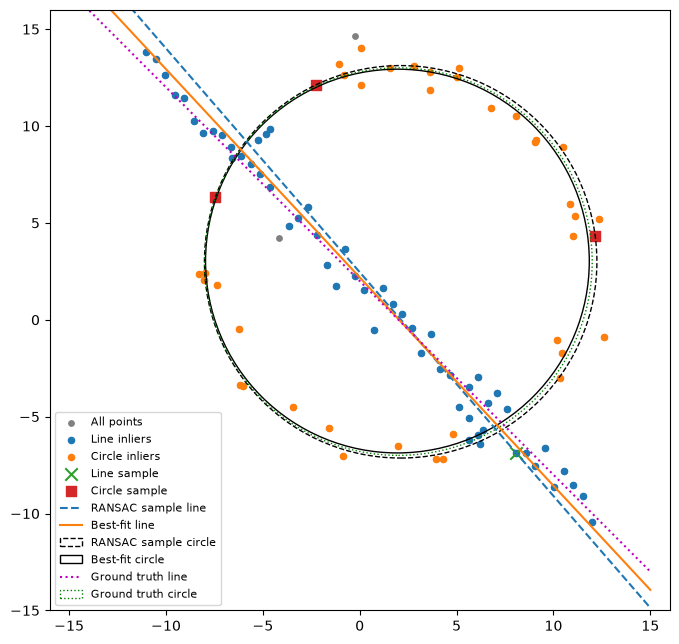

In [66]:

fig, ax = plt.subplots(figsize=(8,8))

ax.scatter(*X.T, s=15, color='gray', label='All points')
ax.scatter(*X[line_inliers].T, s=20, label='Line inliers')
ax.scatter(*X_rem[circle_inliers].T, s=20, label='Circle inliers')

ax.scatter(*line_sample.T, marker='x', s=80, label='Line sample')
ax.scatter(*circle_sample.T, marker='s', s=60, label='Circle sample')

xx = np.linspace(-15,15,100)

for model, style, label in [
    (line_model, '--', 'RANSAC sample line'),
    (best_model_line, '-', 'Best-fit line')
]:
    a,b,d = model
    if abs(b) > 1e-8:
        ax.plot(xx, (d-a*xx)/b, style, label=label)
    else:
        ax.axvline(d/a, linestyle=style, label=label)

for model, style, label in [
    (circle_model, '--', 'RANSAC sample circle'),
    (best_model_circle, '-', 'Best-fit circle')
]:
    ax.add_patch(plt.Circle(
        model[:2], model[2], fill=False,
        linestyle=style, label=label
    ))

# Ground truth
ax.plot(xx, m*xx+2, 'm:', label='Ground truth line')
ax.add_patch(plt.Circle(
    (x0_gt,y0_gt), r, fill=False,
    color='green', linestyle=':', label='Ground truth circle'
))

ax.set_xlim(-16,16)
ax.set_ylim(-15,16)
ax.set_aspect('equal')
ax.legend(fontsize=8)
plt.show()


## Part (d) – What happens if we fit the circle first?
If we fit the circle before the line, RANSAC will attempt to find a circle using the entire dataset. Some line points may be incorrectly selected as circle inliers, particularly near intersections.
The circle can still be estimated correctly, but the probability of selecting three genuine circle points is lower before removing line inliers.

## Question 3



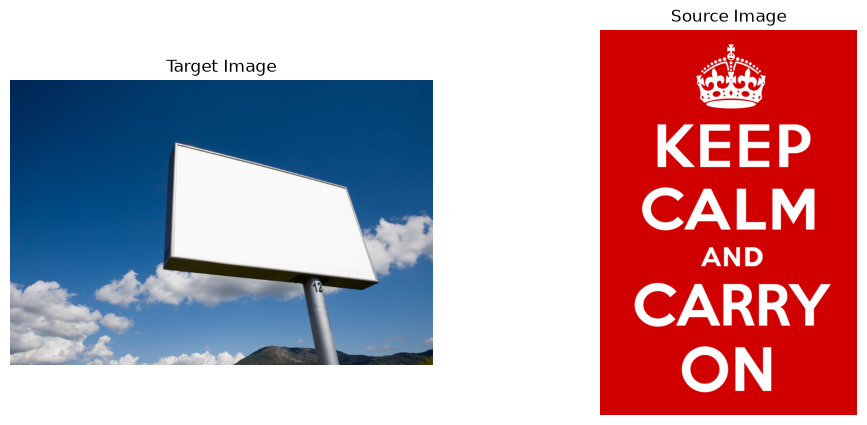

In [67]:

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

target = cv.imread("a2images/board.png")
source = cv.imread("a2images/banner.webp")

assert target is not None and source is not None

target = cv.cvtColor(target, cv.COLOR_BGR2RGB)
source = cv.cvtColor(source, cv.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 2, figsize=(12,5))
ax[0].imshow(target)
ax[0].set_title("Target Image")
ax[1].imshow(source)
ax[1].set_title("Source Image")

for a in ax:
    a.axis("off")
plt.show()


In [80]:

points = []
display_img = cv.cvtColor(target, cv.COLOR_RGB2BGR).copy()

def click(event, x, y, flags, param):
    if event == cv.EVENT_LBUTTONDOWN and len(points) < 4:
        points.append([x, y])
        cv.circle(display_img, (x, y), 5, (0, 0, 255), -1)
        cv.imshow("Select Points", display_img)

cv.namedWindow("Select Points", cv.WINDOW_AUTOSIZE)
cv.imshow("Select Points", display_img)
cv.setMouseCallback("Select Points", click)

while len(points) < 4:
    if cv.waitKey(20) & 0xFF == 27:
        break

cv.destroyAllWindows()

if len(points) != 4:
    raise ValueError("Select exactly four corners.")

dst = np.float32(points)
print("Selected points:\n", dst)


Selected points:
 [[306. 119.]
 [612. 197.]
 [666. 363.]
 [300. 319.]]


In [81]:

h, w = source.shape[:2]

src = np.float32([
    [0, 0],
    [w-1, 0],
    [w-1, h-1],
    [0, h-1]
])

H = cv.getPerspectiveTransform(src, dst)

print("Homography Matrix:\n", H)


Homography Matrix:
 [[ 4.83968934e-01 -4.63581416e-02  3.06000000e+02]
 [ 1.34410952e-01  9.43244927e-02  1.19000000e+02]
 [ 2.69422478e-04 -1.40609254e-04  1.00000000e+00]]


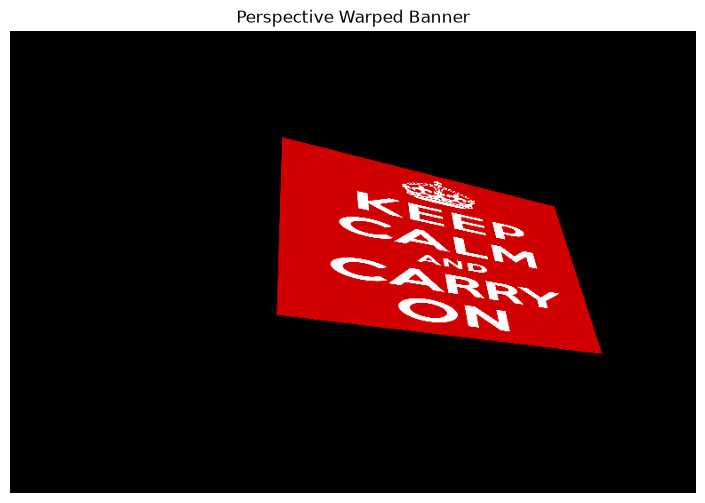

In [82]:

height, width = target.shape[:2]

warped = cv.warpPerspective(source, H, (width, height))

plt.figure(figsize=(10, 6))
plt.imshow(warped)
plt.title("Perspective Warped Banner")
plt.axis("off")
plt.show()


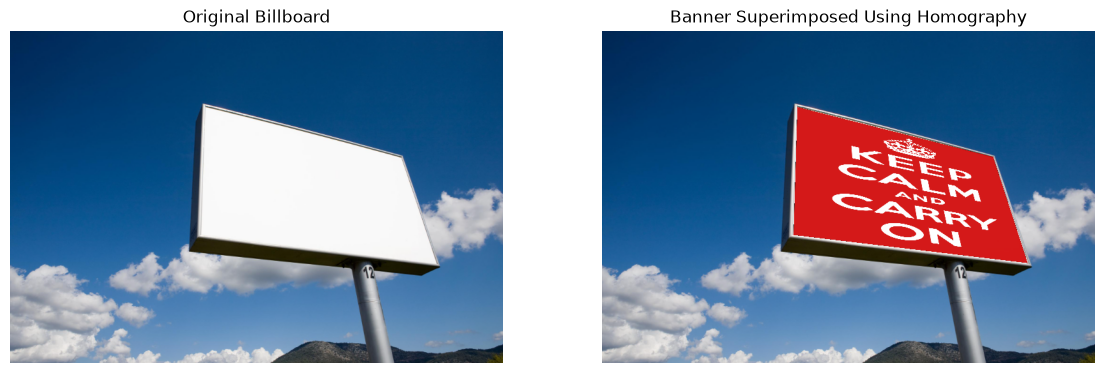

In [83]:

mask = np.ones((h, w), dtype=np.uint8) * 255
mask = cv.warpPerspective(mask, H, (width, height))

alpha = 0.9

blended = cv.addWeighted(target, 1-alpha, warped, alpha, 0)

result = target.copy()
result[mask > 0] = blended[mask > 0]

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].imshow(target)
ax[0].set_title("Original Billboard")

ax[1].imshow(result)
ax[1].set_title("Banner Superimposed Using Homography")

for a in ax:
    a.axis("off")

plt.show()


In [84]:

cv.imwrite(
    "Q3_Result_1.jpg",
    cv.cvtColor(result, cv.COLOR_RGB2BGR)
)


True

Click: Top-left, Top-right, Bottom-right, Bottom-left
Homography Matrix:
 [[ 2.09413451e-01  0.00000000e+00  2.95000000e+02]
 [-2.19806475e-02  2.14285714e-01  1.16000000e+02]
 [-5.97300203e-05  0.00000000e+00  1.00000000e+00]]


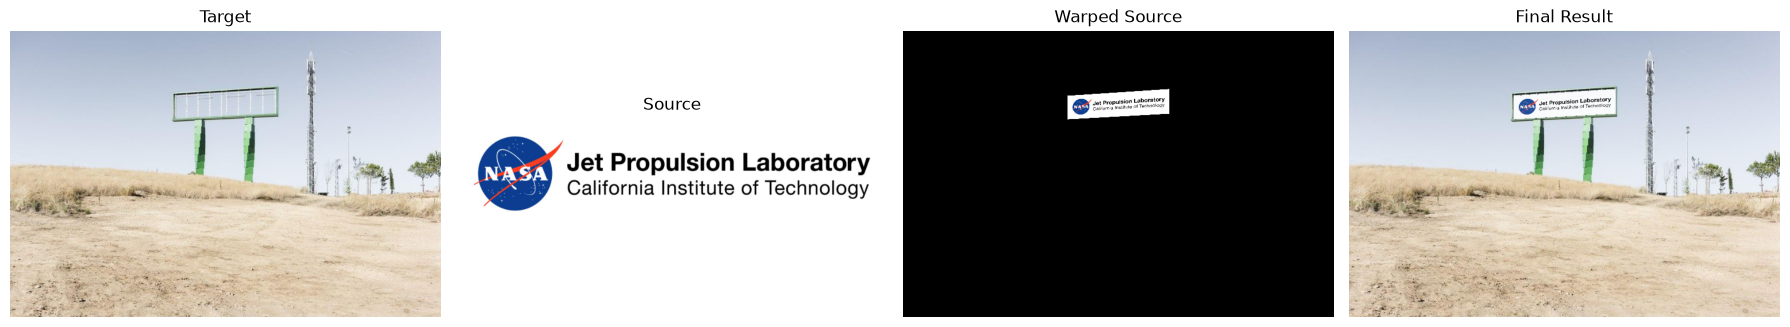

Results saved successfully!


In [85]:

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Load images
target = cv.imread("a2images/board1.png")
source = cv.imread("a2images/nasa.png")

assert target is not None and source is not None, "Check image paths"

target = cv.cvtColor(target, cv.COLOR_BGR2RGB)
source = cv.cvtColor(source, cv.COLOR_BGR2RGB)

# 2. Select four points on target
points = []
display_img = cv.cvtColor(target, cv.COLOR_RGB2BGR).copy()

def click(event, x, y, flags, param):
    if event == cv.EVENT_LBUTTONDOWN and len(points) < 4:
        points.append([x, y])
        cv.circle(display_img, (x, y), 5, (0, 0, 255), -1)
        cv.putText(display_img, str(len(points)), (x+8, y),
                   cv.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
        cv.imshow("Select 4 Corners", display_img)

cv.namedWindow("Select 4 Corners", cv.WINDOW_AUTOSIZE)
cv.imshow("Select 4 Corners", display_img)
cv.setMouseCallback("Select 4 Corners", click)

print("Click: Top-left, Top-right, Bottom-right, Bottom-left")

while len(points) < 4:
    if cv.waitKey(20) & 0xFF == 27:
        break

cv.destroyAllWindows()

if len(points) != 4:
    raise ValueError("Four points must be selected.")

dst = np.float32(points)

# 3. Compute homography
h, w = source.shape[:2]
height, width = target.shape[:2]

src = np.float32([
    [0, 0],
    [w-1, 0],
    [w-1, h-1],
    [0, h-1]
])

H = cv.getPerspectiveTransform(src, dst)
print("Homography Matrix:\n", H)

# 4. Perspective warp
warped = cv.warpPerspective(source, H, (width, height))

# 5. Create mask and blend
mask = np.ones((h, w), dtype=np.uint8) * 255
mask = cv.warpPerspective(mask, H, (width, height))

alpha = 0.9
blended = cv.addWeighted(target, 1-alpha, warped, alpha, 0)

result = target.copy()
result[mask > 0] = blended[mask > 0]

# 6. Display results
fig, ax = plt.subplots(1, 4, figsize=(18, 5))

images = [target, source, warped, result]
titles = ["Target", "Source", "Warped Source", "Final Result"]

for a, image, title in zip(ax, images, titles):
    a.imshow(image)
    a.set_title(title)
    a.axis("off")

plt.tight_layout()
plt.show()

# 7. Save results
cv.imwrite("Q3_Result_2.jpg",
           cv.cvtColor(result, cv.COLOR_RGB2BGR))

fig.savefig("Q3_Stages_2.png", dpi=200, bbox_inches="tight")

print("Results saved successfully!")
